In [1]:
import cv2
import numpy as np
import zxingcpp
import inspect 
from ultralytics import YOLO
from pathlib import Path
import pandas as pd
from preprocessing_variants import preprocess_variants,cylindrical_unwarp_and_threshold
from YOLO_localize import layer1_tiled_yolo_localize
from zxing_decoder import *
# Core computer vision libraries

# Barcode/QR decoding (zxing-cpp Python bindings)

# Ultralytics (YOLO)

# Optional but commonly used for visualization and file handling
import plotly.express as px
import plotly.graph_objects as go

In [11]:
from pathlib import Path
import sys

sys.path.insert(0, str(Path.cwd().resolve().parent))

from main import run_pipeline

crops_dir = Path(r"C:\Users\Anant.Jain\OneDrive - PACCAR Inc\Documents\AI_Initatives\Bar_code_detection\Bottle\Test_single_crop")
results_dir = Path(r"C:\Users\Anant.Jain\OneDrive - PACCAR Inc\Documents\AI_Initatives\Bar_code_detection\Bottle\Test_single_crop_results")

results_dir.mkdir(parents=True, exist_ok=True)

run_pipeline(
    crops_dir=crops_dir,
    results_dir=results_dir,
    workers=1,
    batch_size=1,
    aggressive_max_passes=12,
)

print("CSV files in results dir:")
print(list(results_dir.glob("*.csv")))

2026-10-14 11:50:41,846 | INFO    | Crops dir     : C:\Users\Anant.Jain\OneDrive - PACCAR Inc\Documents\AI_Initatives\Bar_code_detection\Bottle\Test_single_crop
2026-10-14 11:50:41,849 | INFO    | Results dir   : C:\Users\Anant.Jain\OneDrive - PACCAR Inc\Documents\AI_Initatives\Bar_code_detection\Bottle\Test_single_crop_results
2026-10-14 11:50:41,852 | INFO    | Images        : 1
2026-10-14 11:50:41,855 | INFO    | Workers       : 1
2026-10-14 11:50:41,857 | INFO    | Batch size    : 1 (1 batches)
2026-10-14 11:50:41,860 | INFO    | Agg max passes: 12
2026-10-14 11:50:41,862 | INFO    | DataMatrix fmt: Data Matrix
2026-10-14 11:50:41,865 | INFO    | CSV report    : C:\Users\Anant.Jain\OneDrive - PACCAR Inc\Documents\AI_Initatives\Bar_code_detection\Bottle\Test_single_crop_results\decode_report_20261014_115041.csv
2026-10-14 11:50:41,867 | INFO    | Log file      : C:\Users\Anant.Jain\OneDrive - PACCAR Inc\Documents\AI_Initatives\Bar_code_detection\Bottle\Test_single_crop_results\decod

2026-10-14 11:51:06,670 | INFO    | RESULT 8a633805-0512-44ca-a4c5-1385f1752f76.jpg | decoded=False method=none total_ms=24793.40 text=''
2026-10-14 11:51:06,685 | INFO    | Batch 1 done in 24.81 s | decoded so far 0/123
2026-10-14 11:51:06,736 | INFO    | ========== SUMMARY ==========
2026-10-14 11:51:06,746 | INFO    | Total images : 123
2026-10-14 11:51:06,748 | INFO    | Decoded OK   : 0
2026-10-14 11:51:06,750 | INFO    | Failed       : 123
2026-10-14 11:51:06,751 | INFO    | Wall time    : 24.82 s (4.96 img/s)
2026-10-14 11:51:06,753 | INFO    | By method    : {}
2026-10-14 11:51:06,755 | INFO    | CSV written  : C:\Users\Anant.Jain\OneDrive - PACCAR Inc\Documents\AI_Initatives\Bar_code_detection\Bottle\Test_single_crop_results\decode_report_20261014_115041.csv
2026-10-14 11:51:06,759 | INFO    | Also         : C:\Users\Anant.Jain\OneDrive - PACCAR Inc\Documents\AI_Initatives\Bar_code_detection\Bottle\Test_single_crop_results\decode_report_latest.csv

--- Decode Report ---
FILE  

file                         8a633805-0512-44ca-a4c5-1385f1752f76.jpg
size_px                      (211, 221)
sharp_laplacian_var          1348.7826600335677
sharp_tenengrad              64685.04436962536
contrast_p5_p95              236.0
michelson_contrast           0.8872180417773758
otsu_thr                     133.0
dark_ratio                   0.22015397482361518
class_separation_d           5.454471934153779
saturation_pct               4.958075100255195
edge_density_center          0.18269648647745126
edge_density_border          0.036846512740758466
edge_border_ratio            0.2016815607651249
symbol_area_frac             0.10028736248418434
rect_fill_ratio              0.47053267910156554
quiet_zone_px                30.42291259765625
module_pitch_warped_px       16.666666666666668
est_modules_per_side         24
px_per_module_original       4.15388369051121
pitch_consistency_cv         0.5028414055568737
run_grid_misfit              0.2673533246414603
side_dark_fill      

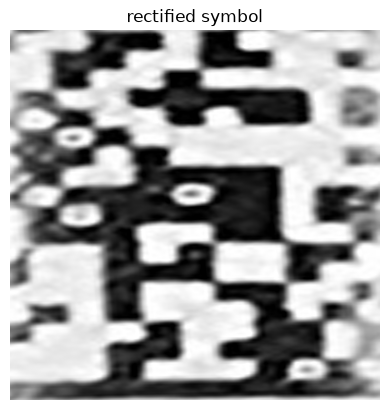

In [1]:
import cv2, numpy as np, zxingcpp
from pathlib import Path

crop_dir = Path(r"C:\Users\Anant.Jain\OneDrive - PACCAR Inc\Documents\AI_Initatives\Bar_code_detection\Bottle\Test_single_crop")
img_path = sorted(p for p in crop_dir.iterdir() if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"})[0]

def runs_of(b):
    out = []
    for row in b:
        d = np.flatnonzero(np.diff(row.astype(np.int8))) + 1
        out.extend(np.diff(np.r_[0, d, len(row)]))
    return np.array(out)

def barcode_quality(path, warp_size=400):
    m = {"file": path.name}
    g = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    m["size_px"] = g.shape[::-1]

    # ---- global quality ----
    m["sharp_laplacian_var"] = float(cv2.Laplacian(g, cv2.CV_64F).var())
    gx, gy = cv2.Sobel(g, cv2.CV_64F, 1, 0), cv2.Sobel(g, cv2.CV_64F, 0, 1)
    m["sharp_tenengrad"] = float(np.mean(gx**2 + gy**2))
    p5, p95 = np.percentile(g, [5, 95])
    m["contrast_p5_p95"] = float(p95 - p5)
    m["michelson_contrast"] = float((p95 - p5) / (p95 + p5 + 1e-6))
    thr, bw = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    if (bw > 0).mean() > 0.6:                      # auto polarity: dark modules = 255
        bw = 255 - bw
    m["otsu_thr"] = float(thr)
    m["dark_ratio"] = float((bw > 0).mean())       # ~0.4-0.6 healthy for DataMatrix/QR
    lo, hi = g[bw == 0], g[bw > 0]
    if len(lo) and len(hi):
        m["class_separation_d"] = float(abs(lo.mean() - hi.mean()) / (np.sqrt((lo.var() + hi.var()) / 2) + 1e-6))
    m["saturation_pct"] = float(((g <= 2) | (g >= 253)).mean() * 100)

    # ---- edge/border ratio ----
    edges = cv2.Canny(g, 50, 150) > 0
    h, w = g.shape
    bh, bw_ = max(1, int(h * .1)), max(1, int(w * .1))
    mask = np.zeros_like(edges); mask[bh:-bh, bw_:-bw_] = True
    m["edge_density_center"] = float(edges[mask].mean())
    m["edge_density_border"] = float(edges[~mask].mean())
    m["edge_border_ratio"] = m["edge_density_border"] / (m["edge_density_center"] + 1e-9)  # low = clean quiet zone

    # ---- localize symbol & rectify ----
    k = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
    closed = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, k)
    cnts, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        m["error"] = "no symbol contour"; return m, None
    c = max(cnts, key=cv2.contourArea)
    rect = cv2.minAreaRect(c)
    box = cv2.boxPoints(rect).astype(np.float32)
    s = np.array([[0, 0], [warp_size-1, 0], [warp_size-1, warp_size-1], [0, warp_size-1]], np.float32)
    # order box: tl,tr,br,bl
    idx = np.argsort(box[:, 1]); top = box[idx[:2]]; bot = box[idx[2:]]
    box = np.array([top[np.argmin(top[:, 0])], top[np.argmax(top[:, 0])], bot[np.argmax(bot[:, 0])], bot[np.argmin(bot[:, 0])]], np.float32)
    M = cv2.getPerspectiveTransform(box, s)
    wg = cv2.warpPerspective(g, M, (warp_size, warp_size), flags=cv2.INTER_CUBIC)
    wb = cv2.warpPerspective(bw, M, (warp_size, warp_size), flags=cv2.INTER_NEAREST) > 0
    m["symbol_area_frac"] = float(cv2.contourArea(c) / (h * w))
    m["rect_fill_ratio"] = float(cv2.contourArea(c) / (rect[1][0] * rect[1][1] + 1e-6))  # solidity
    m["quiet_zone_px"] = float(min(box[:, 0].min(), box[:, 1].min(), w - box[:, 0].max(), h - box[:, 1].max()))

    # ---- module pitch ----
    r = np.r_[runs_of(wb), runs_of(wb.T)]
    r = r[r >= 2]
    p0 = np.percentile(r, 25)
    pitch = float(np.median(r[r <= 1.5 * p0]))
    n = int(round(warp_size / pitch))
    pitch = warp_size / n
    sx = np.sqrt(rect[1][0] * rect[1][1]) / warp_size
    m["module_pitch_warped_px"] = pitch
    m["est_modules_per_side"] = n
    m["px_per_module_original"] = float(pitch * sx)       # zxing: >=~3 good, <2 risky
    q = r / pitch
    m["pitch_consistency_cv"] = float(np.std(q[q < 1.5]) / (np.mean(q[q < 1.5]) + 1e-9))
    m["run_grid_misfit"] = float(np.mean(np.abs(q - np.round(q))))  # 0 = runs fit integer modules

    # ---- L-finder + clock track ----
    pb = max(2, int(round(pitch)))
    sides = {"top": wb[:pb, :], "bottom": wb[-pb:, :], "left": wb[:, :pb].T, "right": wb[:, -pb:].T}
    fill = {k_: float(v.mean()) for k_, v in sides.items()}
    m["side_dark_fill"] = fill
    pairs = [("left", "bottom"), ("left", "top"), ("right", "bottom"), ("right", "top")]
    best = max(pairs, key=lambda p: fill[p[0]] + fill[p[1]])
    m["L_sides"] = best
    m["L_solidity"] = (fill[best[0]] + fill[best[1]]) / 2     # 1.0 = intact L
    m["L_present"] = bool(min(fill[best[0]], fill[best[1]]) > 0.85)
    opp = {"left": "right", "right": "left", "top": "bottom", "bottom": "top"}
    clock_sides = [opp[best[0]], opp[best[1]]]
    alt = []
    for cs in clock_sides:
        band = sides[cs]
        prof = band[: pb // 2 + 1].mean(0) if cs in ("bottom", "right") else band[pb // 2:].mean(0)
        cells = np.array([prof[int(i*pitch):int((i+1)*pitch)].mean() for i in range(n)]) > 0.5
        alt.append(float(np.mean(cells[1:] != cells[:-1])))
    m["clock_alternation"] = alt                              # 1.0 = perfect dark/light alternation

    # ---- module ambiguity / damage proxy ----
    cells = np.array([[wg[int(i*pitch):int((i+1)*pitch), int(j*pitch):int((j+1)*pitch)].mean() for j in range(n)] for i in range(n)])
    t = cells.mean() if False else (np.percentile(cells, 10) + np.percentile(cells, 90)) / 2
    span = np.percentile(cells, 90) - np.percentile(cells, 10) + 1e-6
    amb = np.abs(cells - t) / span < 0.15
    m["ambiguous_module_frac"] = float(amb.mean())
    # ---- damage score (0 intact .. 1 destroyed) ----
    l_dmg = 1 - m["L_solidity"]
    clk_dmg = 1 - float(np.mean(alt))
    m["est_damage_score"] = float(np.clip(0.4*l_dmg + 0.3*clk_dmg + 0.3*min(1, m["ambiguous_module_frac"]*3), 0, 1))

    # ---- zxing ground truth ----
    res = zxingcpp.read_barcodes(g)
    m["zxing_decoded"] = [(x.format.name, x.text) for x in res]
    return m, wg

metrics, rect_img = barcode_quality(img_path)
for k_, v in metrics.items():
    print(f"{k_:28s} {v}")
if rect_img is not None:
    import matplotlib.pyplot as plt
    plt.imshow(rect_img, cmap="gray"); plt.title("rectified symbol"); plt.axis("off"); plt.show()